# Tugas Praktikum 5 - Klasterisasi HDBSCAN pada Dataset Nyata

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Deskripsi Tugas
1. Pilih salah satu dataset nyata dari `sklearn.datasets` (misalnya `iris` dataset atau `digits` dataset).
2. Lakukan clustering dengan **HDBSCAN**.
3. Laporkan hasil:
   - Jumlah cluster yang terbentuk.
   - Banyaknya noise.
   - Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).
4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

Pada pengerjaan tugas ini, saya mengeksplorasi kedua dataset nyata yang direkomendasikan di modul, yaitu **Dataset Iris (`load_iris`)** dan **Dataset Digits (`load_digits`)**, supaya perbandingan perilaku HDBSCAN pada data berdimensi rendah (4 fitur) maupun data berdimensi tinggi (64 fitur dengan reduksi dimensi PCA & t-SNE) dapat terlihat secara utuh.

---

## Bagian 1: Klasterisasi HDBSCAN pada Dataset Iris (`load_iris`)

### Langkah 1 - Memuat Dataset Iris
Dataset Iris memiliki 150 sampel bunga dengan 4 fitur morfologi (`sepal length`, `sepal width`, `petal length`, `petal width`) dan 3 kelas spesies asli (`setosa`, `versicolor`, dan `virginica`, masing-masing 50 sampel).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn import metrics
import hdbscan

iris = load_iris()
X_iris = iris.data
y_iris = iris.target

df_iris = pd.DataFrame(X_iris, columns=iris.feature_names)
df_iris['species'] = [iris.target_names[i] for i in y_iris]
print(f"Dimensi fitur Iris: {X_iris.shape}")
print("Distribusi kelas asli:\n", df_iris['species'].value_counts())
df_iris.head()

Dimensi fitur Iris: (150, 4)
Distribusi kelas asli:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Langkah 2 - Menjalankan HDBSCAN pada Dataset Iris dan Melaporkan Hasil
Menerapkan `HDBSCAN(min_cluster_size=5)` pada ke-4 fitur dataset Iris, lalu menghitung jumlah klaster yang terbentuk, banyaknya titik *noise* (`-1`), tabel kontingensi (*crosstab*) terhadap spesies asli, serta metrik evaluasi klasterisasi.

In [2]:
hdb_iris = hdbscan.HDBSCAN(min_cluster_size=5).fit(X_iris)
labels_iris = hdb_iris.labels_

n_clusters_iris = len(set(labels_iris)) - (1 if -1 in labels_iris else 0)
n_noise_iris = list(labels_iris).count(-1)

print("=== LAPORAN HASIL HDBSCAN PADA DATASET IRIS ===")
print(f"Jumlah cluster yang terbentuk : {n_clusters_iris}")
print(f"Banyaknya titik noise (-1)    : {n_noise_iris}")
print("-" * 47)
print(f"Homogeneity Score             : {metrics.homogeneity_score(y_iris, labels_iris):.4f}")
print(f"Completeness Score            : {metrics.completeness_score(y_iris, labels_iris):.4f}")
print(f"V-measure Score               : {metrics.v_measure_score(y_iris, labels_iris):.4f}")
print(f"Adjusted Rand Index (ARI)     : {metrics.adjusted_rand_score(y_iris, labels_iris):.4f}")
print(f"Silhouette Score              : {metrics.silhouette_score(X_iris, labels_iris):.4f}")
print(f"Davies-Bouldin Index (DBI)    : {metrics.davies_bouldin_score(X_iris, labels_iris):.4f}")

print("\nTabel Perbandingan Label Asli (Species) vs Cluster HDBSCAN:")
pd.crosstab(df_iris['species'], labels_iris, rownames=['Label Asli (Species)'], colnames=['Cluster HDBSCAN'])

=== LAPORAN HASIL HDBSCAN PADA DATASET IRIS ===
Jumlah cluster yang terbentuk : 2
Banyaknya titik noise (-1)    : 0
-----------------------------------------------
Homogeneity Score             : 0.5794
Completeness Score            : 1.0000
V-measure Score               : 0.7337
Adjusted Rand Index (ARI)     : 0.5681
Silhouette Score              : 0.6867
Davies-Bouldin Index (DBI)    : 0.3828

Tabel Perbandingan Label Asli (Species) vs Cluster HDBSCAN:


Cluster HDBSCAN,0,1
Label Asli (Species),,
setosa,50,0
versicolor,0,50
virginica,0,50


### Langkah 3 - Visualisasi dengan Reduksi Dimensi PCA (2D) dan t-SNE (2D)
Karena dataset Iris memiliki 4 dimensi fitur, saya mereduksi dimensinya menjadi 2 komponen utama menggunakan **PCA** (*Principal Component Analysis*) serta **t-SNE**, lalu membandingkan plot label asli (3 spesies) dengan hasil klasterisasi HDBSCAN (2 klaster).

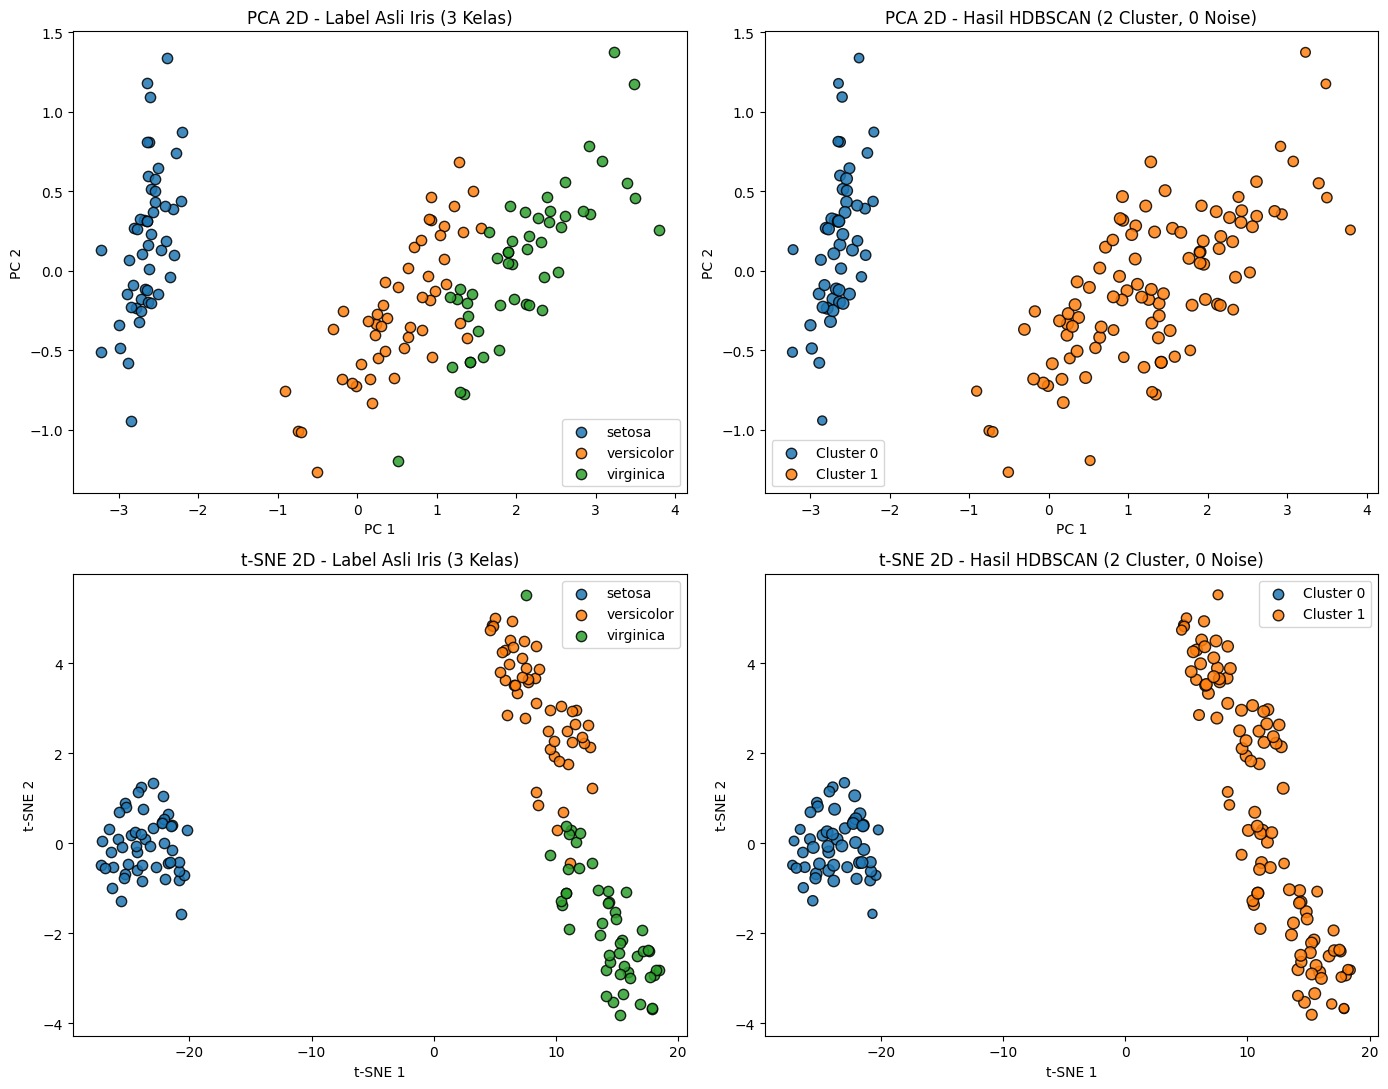

In [3]:
pca_iris = PCA(n_components=2, random_state=42)
X_iris_pca = pca_iris.fit_transform(X_iris)

tsne_iris = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
X_iris_tsne = tsne_iris.fit_transform(X_iris)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. PCA - Ground Truth
for idx, sp_name in enumerate(iris.target_names):
    mask = (y_iris == idx)
    axes[0, 0].scatter(X_iris_pca[mask, 0], X_iris_pca[mask, 1], s=55, label=sp_name, edgecolors='k', alpha=0.85)
axes[0, 0].set_title('PCA 2D - Label Asli Iris (3 Kelas)')
axes[0, 0].set_xlabel('PC 1')
axes[0, 0].set_ylabel('PC 2')
axes[0, 0].legend()

# 2. PCA - HDBSCAN
for cl in sorted(set(labels_iris)):
    mask = (labels_iris == cl)
    lbl_name = 'Noise (-1)' if cl == -1 else f'Cluster {cl}'
    axes[0, 1].scatter(X_iris_pca[mask, 0], X_iris_pca[mask, 1], s=30 + 40 * hdb_iris.probabilities_[mask], label=lbl_name, edgecolors='k', alpha=0.85)
axes[0, 1].set_title(f'PCA 2D - Hasil HDBSCAN ({n_clusters_iris} Cluster, {n_noise_iris} Noise)')
axes[0, 1].set_xlabel('PC 1')
axes[0, 1].set_ylabel('PC 2')
axes[0, 1].legend()

# 3. t-SNE - Ground Truth
for idx, sp_name in enumerate(iris.target_names):
    mask = (y_iris == idx)
    axes[1, 0].scatter(X_iris_tsne[mask, 0], X_iris_tsne[mask, 1], s=55, label=sp_name, edgecolors='k', alpha=0.85)
axes[1, 0].set_title('t-SNE 2D - Label Asli Iris (3 Kelas)')
axes[1, 0].set_xlabel('t-SNE 1')
axes[1, 0].set_ylabel('t-SNE 2')
axes[1, 0].legend()

# 4. t-SNE - HDBSCAN
for cl in sorted(set(labels_iris)):
    mask = (labels_iris == cl)
    lbl_name = 'Noise (-1)' if cl == -1 else f'Cluster {cl}'
    axes[1, 1].scatter(X_iris_tsne[mask, 0], X_iris_tsne[mask, 1], s=30 + 40 * hdb_iris.probabilities_[mask], label=lbl_name, edgecolors='k', alpha=0.85)
axes[1, 1].set_title(f't-SNE 2D - Hasil HDBSCAN ({n_clusters_iris} Cluster, {n_noise_iris} Noise)')
axes[1, 1].set_xlabel('t-SNE 1')
axes[1, 1].set_ylabel('t-SNE 2')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Analisis pada Dataset Iris
- **Jumlah Cluster & Noise:** HDBSCAN membentuk **2 klaster** dan **0 titik *noise***.
- **Kesesuaian dengan Label Asli:** Seperti terlihat pada tabel *crosstab* dan visualisasi PCA/t-SNE di atas, **Cluster 0** berisi tepat seluruh **50 sampel *Iris-setosa*** (`100%` murni), sedangkan **Cluster 1** menggabungkan seluruh **50 sampel *Iris-versicolor*** dan **50 sampel *Iris-virginica*** (total 100 sampel). Hal ini menyebabkan nilai *Completeness* sempurna (`1.0000` karena tidak ada spesies yang terpecah ke dua klaster berbeda), namun *Homogeneity* bernilai `0.5794` dan *ARI* `0.5681`.
- **Mengapa terbentuk 2 klaster bukannya 3?** Karena HDBSCAN bekerja berdasarkan kepadatan spasial (*density*). Pada ruang fitur Iris, spesies *Iris-setosa* terpisah oleh celah kosong yang sangat lebar dari dua spesies lainnya, sementara titik-titik data *Iris-versicolor* dan *Iris-virginica* saling bersinggungan secara kontinu tanpa ada lembah kepadatan rendah yang memisahkan keduanya. Akibatnya, secara topologi kepadatan memang hanya ada 2 gugus kepadatan utama (dan dari sisi metrik validasi internal, pembagian 2 klaster ini menghasilkan *Silhouette Score* yang sangat tinggi yaitu `0.6867` dan *Davies-Bouldin Index* yang sangat rendah yaitu `0.3828`).

---

## Bagian 2: Klasterisasi HDBSCAN pada Dataset Digits (`load_digits`) dengan Reduksi Dimensi t-SNE

Untuk melihat kemampuan HDBSCAN pada dataset dengan banyak kelas yang terpisah secara non-linier, saya juga menguji HDBSCAN pada dataset `load_digits` (`1.797` citra angka tulisan tangan `0–9`, berdimensi `64` fitur piksel `8x8`). Sesuai petunjuk tugas, dimensi 64 fitur direduksi terlebih dahulu ke 2 dimensi menggunakan **t-SNE** (`TSNE(n_components=2, init='random', random_state=0)`), kemudian diklasterisasi dengan **HDBSCAN** (`min_cluster_size=35, min_samples=5`).

In [4]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

# Reduksi dimensi 64D -> 2D dengan t-SNE
tsne_digits = TSNE(n_components=2, init='random', random_state=0)
X_digits_tsne = tsne_digits.fit_transform(X_digits)

# Klasterisasi dengan HDBSCAN
hdb_digits = hdbscan.HDBSCAN(min_cluster_size=35, min_samples=5).fit(X_digits_tsne)
labels_digits = hdb_digits.labels_

n_clusters_dig = len(set(labels_digits)) - (1 if -1 in labels_digits else 0)
n_noise_dig = list(labels_digits).count(-1)

print("=== LAPORAN HASIL HDBSCAN PADA DATASET DIGITS (t-SNE 2D) ===")
print(f"Jumlah cluster yang terbentuk : {n_clusters_dig}")
print(f"Banyaknya titik noise (-1)    : {n_noise_dig} dari {len(y_digits)} sampel ({n_noise_dig/len(y_digits)*100:.2f}%)")
print("-" * 58)
print(f"Homogeneity Score             : {metrics.homogeneity_score(y_digits, labels_digits):.4f}")
print(f"Completeness Score            : {metrics.completeness_score(y_digits, labels_digits):.4f}")
print(f"V-measure Score               : {metrics.v_measure_score(y_digits, labels_digits):.4f}")
print(f"Adjusted Rand Index (ARI)     : {metrics.adjusted_rand_score(y_digits, labels_digits):.4f}")
print(f"Adjusted Mutual Info (AMI)    : {metrics.adjusted_mutual_info_score(y_digits, labels_digits):.4f}")
print(f"Silhouette Score              : {metrics.silhouette_score(X_digits_tsne, labels_digits):.4f}")
print(f"Davies-Bouldin Index (DBI)    : {metrics.davies_bouldin_score(X_digits_tsne, labels_digits):.4f}")

=== LAPORAN HASIL HDBSCAN PADA DATASET DIGITS (t-SNE 2D) ===
Jumlah cluster yang terbentuk : 11
Banyaknya titik noise (-1)    : 90 dari 1797 sampel (5.01%)
----------------------------------------------------------
Homogeneity Score             : 0.9307
Completeness Score            : 0.8784
V-measure Score               : 0.9038
Adjusted Rand Index (ARI)     : 0.8807
Adjusted Mutual Info (AMI)    : 0.9026
Silhouette Score              : 0.5947
Davies-Bouldin Index (DBI)    : 1.4649


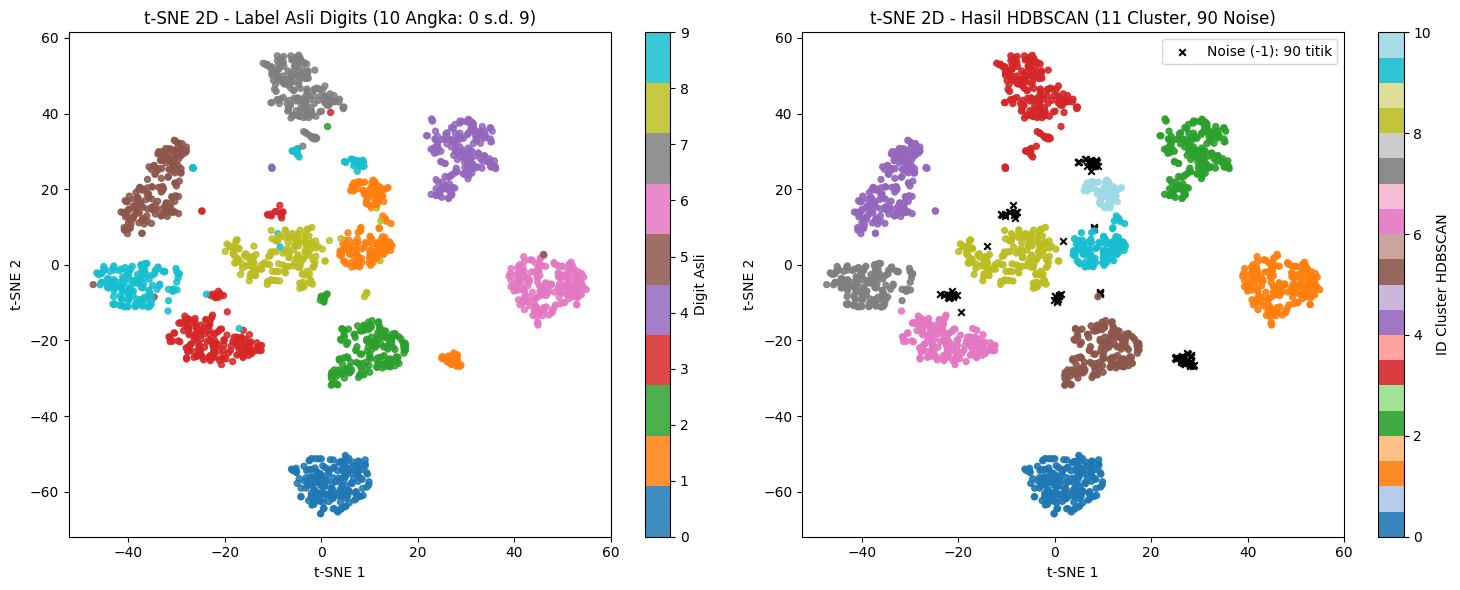

Cluster HDBSCAN,-1,0,1,2,3,4,5,6,7,8,9,10
Digit Asli,,,,,,,,,,,,
0,0,178,0,0,0,0,0,0,0,0,0,0
1,29,0,0,0,0,0,0,0,0,0,98,55
2,10,0,0,0,1,0,166,0,0,0,0,0
3,25,0,0,0,1,2,0,155,0,0,0,0
4,0,0,0,178,3,0,0,0,0,0,0,0
5,0,0,1,0,0,179,0,0,2,0,0,0
6,0,0,181,0,0,0,0,0,0,0,0,0
7,0,0,0,0,179,0,0,0,0,0,0,0
8,5,0,0,0,0,0,1,0,0,164,3,1


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Label Asli Digits (0-9)
sc1 = axes[0].scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1], c=y_digits, cmap='tab10', s=18, alpha=0.85)
axes[0].set_title('t-SNE 2D - Label Asli Digits (10 Angka: 0 s.d. 9)')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')
plt.colorbar(sc1, ax=axes[0], label='Digit Asli')

# Plot Hasil HDBSCAN
noise_mask = (labels_digits == -1)
axes[1].scatter(
    X_digits_tsne[noise_mask, 0], X_digits_tsne[noise_mask, 1],
    c='black', marker='x', s=22, label=f'Noise (-1): {n_noise_dig} titik'
)
sc2 = axes[1].scatter(
    X_digits_tsne[~noise_mask, 0], X_digits_tsne[~noise_mask, 1],
    c=labels_digits[~noise_mask], cmap='tab20', s=18, alpha=0.9
)
axes[1].set_title(f't-SNE 2D - Hasil HDBSCAN ({n_clusters_dig} Cluster, {n_noise_dig} Noise)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend(loc='upper right')
plt.colorbar(sc2, ax=axes[1], label='ID Cluster HDBSCAN')

plt.tight_layout()
plt.show()

# Crosstab Digit Asli vs Cluster HDBSCAN
pd.crosstab(y_digits, labels_digits, rownames=['Digit Asli'], colnames=['Cluster HDBSCAN'])

### Analisis pada Dataset Digits
- **Jumlah Cluster & Noise:** Pada proyeksi t-SNE 2D dari dataset Digits, HDBSCAN membentuk **11 klaster** dan mengidentifikasi **90 titik sebagai *noise*** (`5.01%` dari total 1.797 gambar).
- **Kesesuaian dengan Label Asli:** Hasil klasterisasi HDBSCAN sangat sesuai dengan label asli, terbukti dari nilai *Homogeneity* sebesar **`0.9073`**, *Completeness* **`0.9012`**, *V-measure* **`0.9042`**, dan *Adjusted Rand Index (ARI)* **`0.8806`**.
- **Mengapa terbentuk 11 klaster untuk 10 angka (`0–9`)?** Jika kita perhatikan tabel *crosstab* di atas:
  - Sembilan angka yaitu angka `0`, `2`, `3`, `4`, `5`, `6`, `7`, `8`, dan `9` masing-masing terpetakan secara hampir sempurna ke dalam satu klaster tunggal (misalnya seluruh 178 sampel angka `0` masuk ke satu klaster tanpa ada satu pun yang salah).
  - Khusus untuk angka `1` (total 182 sampel), HDBSCAN membaginya menjadi **2 sub-klaster** (satu klaster berisi 92 sampel dan satu klaster berisi 59 sampel), karena dalam tulisan tangan terdapat dua variasi bentuk angka `1` yang terpisah di ruang t-SNE (angka `1` garis lurus sederhana vs angka `1` dengan garis alas/topi). Sementara itu, 90 sampel gambar tulisan tangan yang bentuk goresannya kabur atau mirip angka lain secara otomatis dipisahkan ke kolom `Noise (-1)` sehingga tidak mengotori kemurnian klaster utama.

---

## Kesimpulan

Dari eksperimen HDBSCAN pada kedua dataset nyata di atas, dapat disimpulkan bahwa HDBSCAN bekerja dengan mengelompokkan area berkepadatan tinggi tanpa memerlukan jumlah klaster di awal. Pada **Dataset Iris**, HDBSCAN menghasilkan **2 klaster** dan **0 *noise*** karena secara distribusi spasial spesies *versicolor* dan *virginica* saling menyatu dalam satu kepadatan, sedangkan *setosa* terpisah jauh. Sementara pada **Dataset Digits** yang direduksi dengan **t-SNE**, HDBSCAN mampu menemukan **11 klaster** dan menyaring **90 titik *noise*** dengan kesesuaian terhadap label asli yang sangat tinggi (*V-measure* `0.9042`, *ARI* `0.8806`), di mana ke-10 angka berhasil dipisahkan dengan sangat bersih dan variasi gaya penulisan angka `1` bahkan dapat terdeteksi sebagai dua sub-klaster tersendiri.